# Forty years of change on one hillside

**Reading an ArcGIS image service with `georest.restesri.services`**

Image services serve rasters you can query, not just look at: the value at a point, statistics
over an area, a picture of any extent. This notebook uses one of them, the Forest Service's
Landscape Change Monitoring System (LCMS) annual change maps, published on the Interagency
Imagery Portal, to follow a patch of the Colorado Rockies through 1985 to 2025. It sits inside
the 2020 Cameron Peak fire, and you will watch that history show up in the data:

1. what the service offers,
2. one point, year by year,
3. an area, as acres per class, and
4. the picture itself.

```bash
pip install georest plotly
```

In [1]:
import math

import pandas as pd
import plotly.express as px
import plotly.io as pio
from IPython.display import Image, display

from georest.restesri import portal, services

pio.renderers.default = "notebook_connected"   # interactive here and on georest.io

LCMS = ("https://imagery.geoplatform.gov/iipp/rest/services/Vegetation/"
        "USFS_EDW_LCMS_AnnualChange_CONUS/ImageServer")

## 1. What the service offers

`getServiceMetadata` reads the service description; `getSupportedOperations` lists what you can
ask it to do.

In [2]:
meta = portal.getServiceMetadata(LCMS)
first_year, last_year = (pd.to_datetime(t, unit="ms").year for t in meta["timeInfo"]["timeExtent"])
print(meta["name"])
print(f"{meta['bandCount']} band of {meta['pixelType']} at {meta['pixelSizeX']:.0f} map units, "
      f"one raster per year, {first_year} to {last_year}")
print("Operations:", ", ".join(op["name"] for op in services.getSupportedOperations(LCMS)))

Vegetation/USFS_EDW_LCMS_AnnualChange_CONUS
1 band of U8 at 30 map units, one raster per year, 1985 to 2025


Operations: Export Image, Query, Identify, Measure, Compute Histograms, Compute Statistics Histograms, Get Samples, Compute Class Statistics, Query GPS Info, Find Images, Image to Map, Map to Image, Measure from Image, Image to Map Multiray, Query Boundary, Compute Pixel Location, Compute Angles, Validate, Project


Each pixel holds a class number. These are the 16 LCMS change classes, with the colors LCMS
uses for them:

In [3]:
CLASSES = {
    1: ("Wind", "#FF09F3"), 2: ("Hurricane", "#541AFF"), 3: ("Snow or Ice Transition", "#E4F5FD"),
    4: ("Desiccation", "#CC982E"), 5: ("Inundation", "#0ADAFF"), 6: ("Prescribed Fire", "#A10018"),
    7: ("Wildfire", "#D54309"), 8: ("Mechanical Land Transformation", "#FAFA4B"),
    9: ("Tree Removal", "#AFDE1C"), 10: ("Defoliation", "#FFC80D"),
    11: ("Southern Pine Beetle", "#A64C28"), 12: ("Insect, Disease, or Drought Stress", "#F39268"),
    13: ("Other Loss", "#C291D5"), 14: ("Vegetation Growth", "#00A398"),
    15: ("Stable", "#3D4551"), 16: ("Non-Processing Area Mask", "#1B1716"),
}
COLOR = {name: color for name, color in CLASSES.values()}


def year_only(year):
    """A mosaic rule that shows a single year's raster."""
    return {"mosaicMethod": "esriMosaicAttribute", "sortField": "year", "where": f"year = {year}"}

## 2. One point, year by year

`identifyPixelValue` returns the class at a point. Asking once per year, with a mosaic rule that
picks that year's raster, gives the point's whole history. Hover for each year's class.

In [4]:
POINT = (-105.75, 40.62)   # longitude, latitude, inside the Cameron Peak burn

history = pd.DataFrame([
    {"year": year,
     "class": CLASSES[int(services.identifyPixelValue(LCMS, *POINT, mosaic_rule=year_only(year))["value"])][0]}
    for year in range(first_year, last_year + 1)
])

fig = px.scatter(history, x="year", y=[""] * len(history), color="class",
                 color_discrete_map=COLOR, labels={"y": "", "year": ""},
                 title=f"LCMS change class at {POINT[1]}, {POINT[0]}, every year")
fig.update_traces(marker=dict(size=18, symbol="square"),
                  hovertemplate="%{x}: %{customdata[0]}<extra></extra>",
                  customdata=history[["class"]])
fig.update_layout(height=260, yaxis_visible=False, legend_title_text="")
fig.show()

history[history["class"] != "Stable"]

,year,class
16,2001,"Insect, Disease, or Drought Stress"
17,2002,"Insect, Disease, or Drought Stress"
18,2003,"Insect, Disease, or Drought Stress"
19,2004,"Insect, Disease, or Drought Stress"
20,2005,"Insect, Disease, or Drought Stress"
21,2006,"Insect, Disease, or Drought Stress"
22,2007,"Insect, Disease, or Drought Stress"
23,2008,"Insect, Disease, or Drought Stress"
24,2009,"Insect, Disease, or Drought Stress"
25,2010,"Insect, Disease, or Drought Stress"


The years of insect and drought stress before the fire are the mountain pine beetle outbreak
that swept these forests. The fire burned in late 2020 and shows up as **Wildfire** in 2021,
the first growing season after it; then the vegetation starts to come back.

## 3. An area: acres per class

`computeStatisticsHistograms` counts the pixels of each class inside a polygon. Converting
counts to acres needs care: this service is in Web Mercator, where a "30 meter" pixel covers
less ground the farther you are from the equator, by a factor of cos(latitude) in each
direction. At 40.6 degrees north a pixel is about 22.8 meters across, not 30. Skipping that
correction would overstate every area here by about 73%.

In [5]:
BOX = {"rings": [[[-105.9, 40.55], [-105.6, 40.55], [-105.6, 40.7],
                  [-105.9, 40.7], [-105.9, 40.55]]],
       "spatialReference": {"wkid": 4326}}
middle_latitude = (40.55 + 40.7) / 2
acres_per_pixel = (meta["pixelSizeX"] * math.cos(math.radians(middle_latitude))) ** 2 / 4046.8564224


def acres_by_class(year):
    hist = services.computeStatisticsHistograms(LCMS, BOX, mosaic_rule=year_only(year))[0]["histogram"]
    # Bin i covers class value i (the histogram runs from -0.5 in steps of 1).
    return {CLASSES[i][0]: n * acres_per_pixel for i, n in enumerate(hist["counts"]) if n and i in CLASSES}


area = pd.DataFrame([{"year": y, "class": c, "acres": a}
                     for y in (2019, 2021, 2024) for c, a in acres_by_class(y).items()])
box_acres = area[area["year"] == 2019]["acres"].sum()
print(f"The box covers {box_acres:,.0f} acres.")

fig = px.bar(area, x="year", y="acres", color="class", color_discrete_map=COLOR,
             category_orders={"class": [name for name, _ in CLASSES.values()]},
             labels={"acres": "Acres", "year": ""},
             title=f"The same {box_acres:,.0f} acres before, just after, and three years after the fire")
fig.update_xaxes(type="category")
fig.update_traces(hovertemplate="%{fullData.name}: %{y:,.0f} acres<extra></extra>")
fig.update_layout(legend_title_text="")
fig.show()

The box covers 104,518 acres.


## 4. The picture

`exportImage` renders any extent of one year as an image, here a PNG with the service's own
colors. 2019, then 2021:

2019


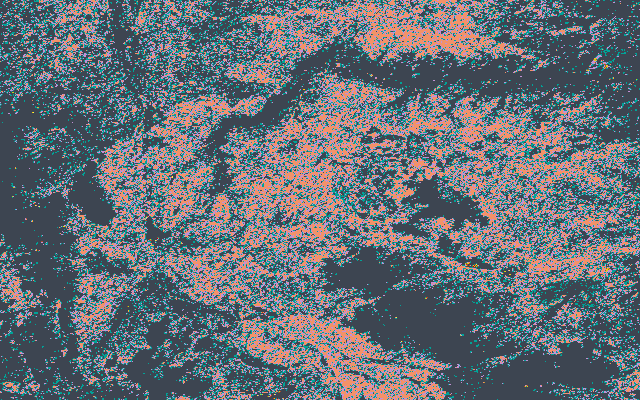

2021


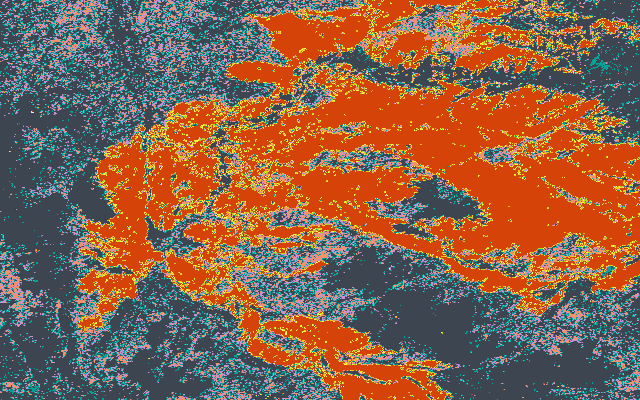

In [6]:
for year in (2019, 2021):
    png = services.exportImage(LCMS, bbox=(-105.95, 40.5, -105.55, 40.75), size=(640, 400),
                               image_format="png", mosaic_rule=year_only(year))
    print(year)
    display(Image(png))

## Where to go next

* **Any point or area.** Change `POINT` and `BOX`; the service covers the conterminous US.
* **Many points at once.** `services.getSamples(LCMS, [(x, y), ...])` samples a list of points
  in one request.
* **Other image services.** The same calls work on any ArcGIS ImageServer; find them with
  `portal.searchPortal("land cover", portal="iipp")`.
* **The other LCMS products**, land cover and land use, and summaries for whole counties, are
  in [`georest.restusfs.lcms`](https://georest.io/info/georest.restusfs.lcms).

Full reference: [`georest.restesri.services`](https://georest.io/info/georest.restesri.services).